In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("online_shoppers_intention.csv")

df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
df.shape

(12330, 18)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [6]:
df.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [7]:
df["Revenue"].value_counts()

Revenue
False    10422
True      1908
Name: count, dtype: int64

In [8]:
df["Revenue"].value_counts(normalize=True)

Revenue
False    0.845255
True     0.154745
Name: proportion, dtype: float64

## Feature Engineering and Encoding

This section identifies numerical and categorical variables and prepares features for predictive modeling.

In [9]:
categorical_check = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

for column in categorical_check:
    print(f"\n{column}:")
    print(df[column].value_counts().sort_index())


Month:
Month
Aug      433
Dec     1727
Feb      184
Jul      432
June     288
Mar     1907
May     3364
Nov     2998
Oct      549
Sep      448
Name: count, dtype: int64

OperatingSystems:
OperatingSystems
1    2585
2    6601
3    2555
4     478
5       6
6      19
7       7
8      79
Name: count, dtype: int64

Browser:
Browser
1     2462
2     7961
3      105
4      736
5      467
6      174
7       49
8      135
9        1
10     163
11       6
12      10
13      61
Name: count, dtype: int64

Region:
Region
1    4780
2    1136
3    2403
4    1182
5     318
6     805
7     761
8     434
9     511
Name: count, dtype: int64

TrafficType:
TrafficType
1     2451
2     3913
3     2052
4     1069
5      260
6      444
7       40
8      343
9       42
10     450
11     247
12       1
13     738
14      13
15      38
16       3
17       1
18      10
19      17
20     198
Name: count, dtype: int64

VisitorType:
VisitorType
New_Visitor           1694
Other                   85
Returning_Visitor

In [10]:
numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

target = "Revenue"

In [11]:
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Target:", target)

Numerical features: 10
Categorical features: 7
Target: Revenue


### Engineered Features

New features are created from existing session variables to summarize overall visitor engagement.

In [31]:
def add_engineered_features(data):
    """Create engagement features from existing session variables."""
    data = data.copy()

    data["TotalPages"] = (
        data["Administrative"]
        + data["Informational"]
        + data["ProductRelated"]
    )

    data["TotalDuration"] = (
        data["Administrative_Duration"]
        + data["Informational_Duration"]
        + data["ProductRelated_Duration"]
    )

    data["AvgDurationPerPage"] = (
        data["TotalDuration"]
        / data["TotalPages"].replace(0, 1)
    )

    return data

In [49]:
df_features = add_engineered_features(df)

In [50]:
df_features[
    ["TotalPages", "TotalDuration", "AvgDurationPerPage"]
].describe()

,TotalPages,TotalDuration,AvgDurationPerPage
count,12330.000000,12330.000000,12330.000000
mean,34.550203,1310.037228,37.792041
std,46.514053,2037.801702,43.420719
min,0.000000,0.000000,0.000000
25%,8.000000,222.000000,18.228465
50%,20.000000,680.000000,29.691872
75%,42.000000,1626.908333,45.421171
max,746.000000,69921.647230,1411.000000


In [51]:
df_features[
    [
        "Administrative",
        "Informational",
        "ProductRelated",
        "TotalPages",
        "TotalDuration",
        "AvgDurationPerPage",
        "Revenue"
    ]
].head()

,Administrative,Informational,ProductRelated,TotalPages,TotalDuration,AvgDurationPerPage,Revenue
0,0,0,1,1,0.000000,0.000000,False
1,0,0,2,2,64.000000,32.000000,False
2,0,0,1,1,0.000000,0.000000,False
3,0,0,2,2,2.666667,1.333333,False
4,0,0,10,10,627.500000,62.750000,False


## Data Visualization and Storytelling

The following visualizations examine customer conversion and session engagement to identify patterns that may be useful for predicting purchases.

In [52]:
conversion_rate = df_features["Revenue"].value_counts(normalize=True) * 100

conversion_rate

Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64

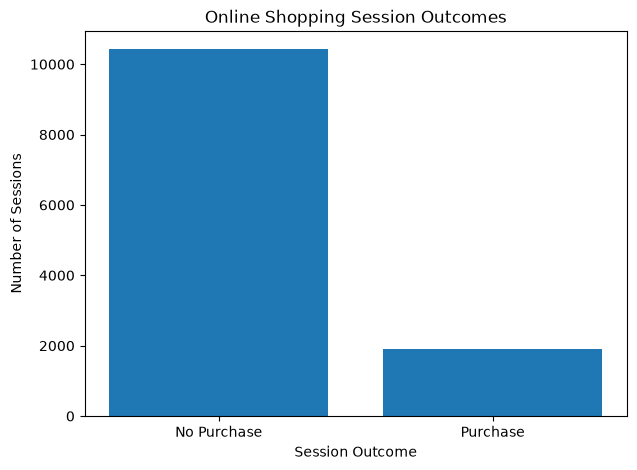

In [53]:
conversion_counts = df_features["Revenue"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(
    ["No Purchase", "Purchase"],
    [conversion_counts[False], conversion_counts[True]]
)

plt.title("Online Shopping Session Outcomes")
plt.xlabel("Session Outcome")
plt.ylabel("Number of Sessions")
plt.show()

### Conversion Rate

Approximately 15.5% of the shopping sessions resulted in a purchase, while about 84.5% did not. This indicates that purchases represent the minority outcome in the dataset. This class imbalance should be considered when evaluating predictive models.

In [54]:
df_features.groupby("Revenue")["TotalPages"].describe()

,count,mean,std,min,25%,50%,75%,max
Revenue,,,,,,,,
False,10422.0,31.284206,42.693917,0.0,7.0,18.0,38.0,746.0
True,1908.0,52.389937,60.417191,1.0,17.0,32.0,62.0,543.0


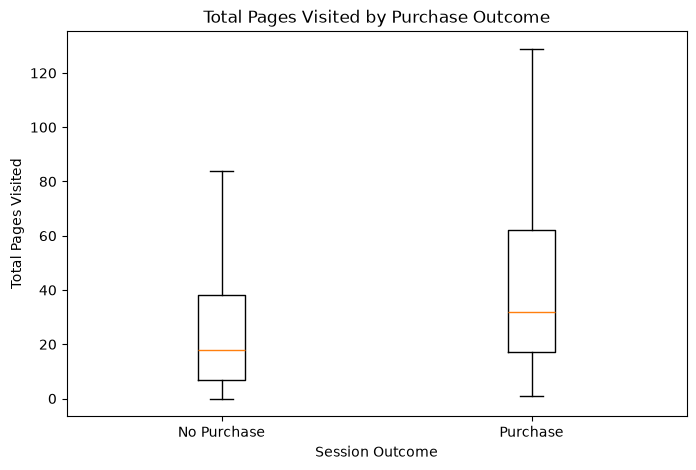

In [55]:
purchase_pages = df_features.loc[
    df_features["Revenue"] == True, "TotalPages"
]

nonpurchase_pages = df_features.loc[
    df_features["Revenue"] == False, "TotalPages"
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [nonpurchase_pages, purchase_pages],
    tick_labels=["No Purchase", "Purchase"],
    showfliers=False
)

plt.title("Total Pages Visited by Purchase Outcome")
plt.xlabel("Session Outcome")
plt.ylabel("Total Pages Visited")
plt.show()

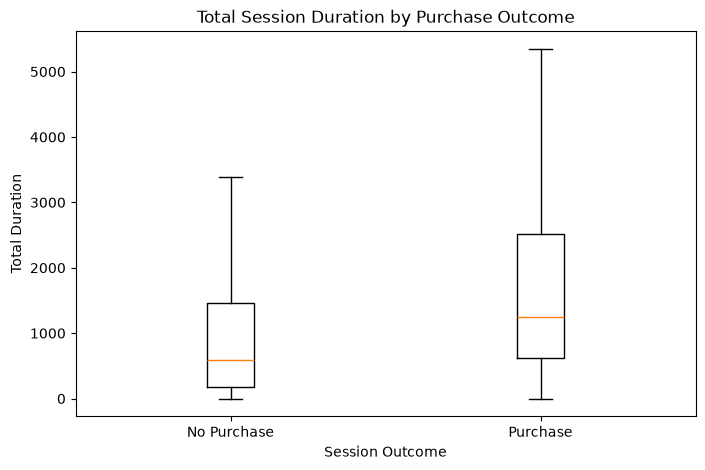

In [56]:
purchase_duration = df_features.loc[
    df_features["Revenue"] == True, "TotalDuration"
]

nonpurchase_duration = df_features.loc[
    df_features["Revenue"] == False, "TotalDuration"
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [nonpurchase_duration, purchase_duration],
    tick_labels=["No Purchase", "Purchase"],
    showfliers=False
)

plt.title("Total Session Duration by Purchase Outcome")
plt.xlabel("Session Outcome")
plt.ylabel("Total Duration")
plt.show()

### Pages Visited and Purchase Behavior

Sessions that resulted in a purchase showed greater browsing activity than sessions that did not. Purchasing sessions visited an average of approximately 52 pages compared with 31 pages for non-purchasing sessions. The median was also higher for purchasing sessions (32 pages versus 18 pages), suggesting that greater website engagement may be associated with conversion.

In [57]:
df_features.groupby("Revenue")["TotalDuration"].describe()

,count,mean,std,min,25%,50%,75%,max
Revenue,,,,,,,,
False,10422.0,1173.964158,1925.426959,0.0,183.666667,588.166667,1464.005253,69921.647230
True,1908.0,2053.304285,2436.111519,0.0,620.358974,1252.075000,2513.856331,28450.201097


In [58]:
df_features.groupby("Revenue")["AvgDurationPerPage"].describe()

,count,mean,std,min,25%,50%,75%,max
Revenue,,,,,,,,
False,10422.0,37.016487,45.794450,0.0,17.040550,28.298458,44.250039,1411.0
True,1908.0,42.028320,26.605448,0.0,25.404241,36.259873,50.754527,354.0


In [59]:
visitor_conversion = (
    df_features.groupby("VisitorType")["Revenue"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

visitor_conversion["ConversionRate"] = visitor_conversion["mean"] * 100

visitor_conversion

,count,mean,ConversionRate
VisitorType,,,
New_Visitor,1694,0.249115,24.911452
Other,85,0.188235,18.823529
Returning_Visitor,10551,0.139323,13.932329


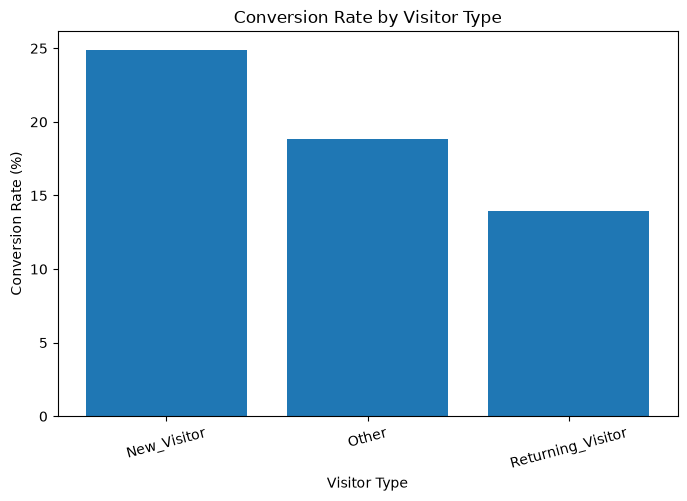

In [60]:
visitor_rates = (
    df_features.groupby("VisitorType")["Revenue"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
plt.bar(visitor_rates.index, visitor_rates.values)

plt.title("Conversion Rate by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=15)
plt.show()

In [61]:
month_conversion = (
    df_features.groupby("Month")["Revenue"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

month_conversion

Month
Nov     25.350233
Oct     20.947177
Sep     19.196429
Aug     17.551963
Jul     15.277778
Dec     12.507238
May     10.850178
June    10.069444
Mar     10.068170
Feb      1.630435
Name: Revenue, dtype: float64

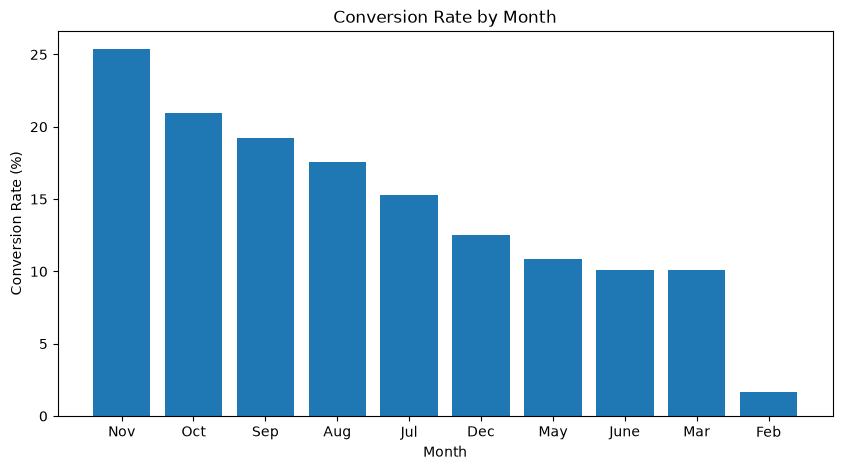

In [62]:
plt.figure(figsize=(10, 5))
plt.bar(month_conversion.index, month_conversion.values)

plt.title("Conversion Rate by Month")
plt.xlabel("Month")
plt.ylabel("Conversion Rate (%)")
plt.show()

### Session Duration and Purchase Behavior

Sessions that resulted in a purchase also tended to last longer. The median total session duration was approximately 1,252 seconds for purchasing sessions compared with 588 seconds for non-purchasing sessions. This suggests that greater overall engagement with the website may be associated with conversion.

### Average Time per Page

Purchasing sessions also spent somewhat more time per page than non-purchasing sessions. However, the difference is smaller than the differences observed for total pages visited and total session duration. This may indicate that overall engagement is more informative than time spent on an individual page.

### Conversion by Visitor Type

New visitors had the highest observed conversion rate at approximately 24.9%, compared with 13.9% for returning visitors. This suggests that visitor type may contain useful information for predicting purchase behavior. The "Other" visitor category contains relatively few observations, so its conversion rate should be interpreted cautiously.

### Conversion by Month

Conversion rates varied considerably by month. November had the highest observed conversion rate at approximately 25.4%, followed by October and September. This suggests that seasonality may be an important factor in online purchasing behavior.

In [63]:
weekend_conversion = (
    df_features.groupby("Weekend")["Revenue"]
    .agg(["count", "mean"])
)

weekend_conversion["ConversionRate"] = (
    weekend_conversion["mean"] * 100
)

weekend_conversion

,count,mean,ConversionRate
Weekend,,,
False,9462,0.148911,14.891144
True,2868,0.173989,17.398884


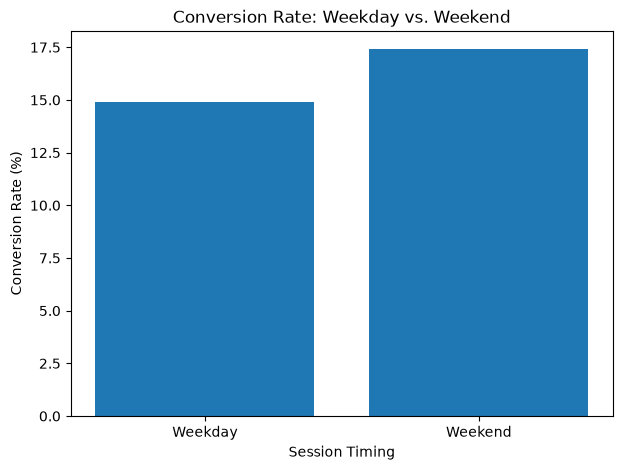

In [64]:
weekend_rates = (
    df_features.groupby("Weekend")["Revenue"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(7, 5))
plt.bar(
    ["Weekday", "Weekend"],
    [weekend_rates[False], weekend_rates[True]]
)

plt.title("Conversion Rate: Weekday vs. Weekend")
plt.xlabel("Session Timing")
plt.ylabel("Conversion Rate (%)")
plt.show()

### Conversion by Session Timing

Weekend sessions had a conversion rate of approximately 17.4%, compared with 14.9% for weekday sessions. This suggests that session timing may provide some predictive information, although the difference is relatively modest.